In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import gaussian_kde
from sklearn.decomposition import PCA
import scanpy as sc
import anndata
from noise_model import *
import torch
import pickle
import seaborn as sns

## Compute Unspliced/Spliced shift per Cell type

In [2]:
data = sc.read_h5ad('INPUT/scRNAseq/scRNAseq_full.h5ad')
data.obs.set_index('CellID', inplace=True)
annotation = pd.read_csv('INPUT/scRNAseq/Trajectory_node_assignement.csv').set_index('CellID')
new_obs = data.obs.merge(annotation,left_index= True, right_index=True, how = 'inner')
data = data[new_obs.index]
data.obs = new_obs
data.layers['spliced'] = data.layers['spliced'].todense()
data.layers['unspliced'] = data.layers['unspliced'].todense()
data = data[data.obs.Condition == 'ctrl']

/home/mleonard/miniconda3/envs/2_scvelo/lib/python3.8/site-packages/anndata/_core/anndata.py:1838: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [3]:
#Drop duplicates
data = data[~data.obs.index.duplicated(keep= 'first')]

# Drop extreme cells
data = data[data.layers['spliced'].sum(1) > np.percentile(data.layers['spliced'].sum(1), 2)]
data = data[data.layers['spliced'].sum(1) < np.percentile(data.layers['spliced'].sum(1), 98)]
data.var.index = data.var.index.str.upper()

# Drop genes with low U
U_not_null = data.layers['unspliced'].sum(axis = 0) > 5/100*data.shape[0]
data = data[:,U_not_null]

S_not_null = data.layers['spliced'].sum(axis = 0) > 5/100*data.shape[0]
data = data[:,S_not_null]



In [4]:

ectoderm = ['Neuroectoderm/NMPs', 'Early neuroectoderm/NMPs' ]
endoderm = ['Endoderm', 'Early endoderm' ]
mesoderm = [ 'Cardiac mesoderm', 'Early cardiac mesoderm', 'Early somitic mesoderm','Somitic mesoderm' ]
primitive_tissues = ['Epiblast','Ectopic pluripotency', 'Primitive streak' , 'Naive pluripotency']
porcn_cluster = ['Wnt. inh. state']

# Create an empty dictionary to store the mappings
germ_layers = {}

# Populate the dictionary with the mappings
for item in ectoderm:
    germ_layers[item] = 'Neuroectoderm/NMPs'

for item in endoderm:
    germ_layers[item] = 'Endoderm'

for item in mesoderm:
    germ_layers[item] = 'Mesoderm'

for item in primitive_tissues:
    germ_layers[item] = 'Early tissues'

for item in porcn_cluster:
    germ_layers[item] = 'Wnt. inhibitor'

data.obs['BIG_celltype'] = data.obs['Cell type'].map(germ_layers)

/tmp/ipykernel_1733878/3913244181.py:26: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  data.obs['BIG_celltype'] = data.obs['Cell type'].map(germ_layers)


In [5]:
def make_design_matrix(cell_identifiers):
    design_matrix = torch.hstack([(cell_identifiers == v).type(torch.int64).reshape(len(cell_identifiers), 
                                                              1) for i, v in enumerate(torch.unique(cell_identifiers))])
    return design_matrix


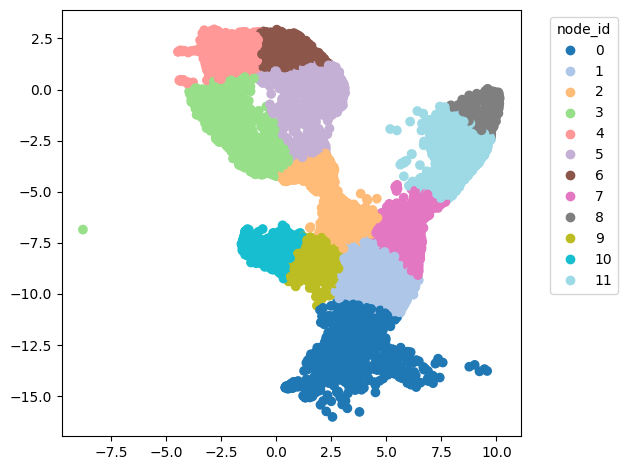

In [6]:
import matplotlib.pyplot as plt
import numpy as np

sc = plt.scatter(
    data.obs["Z_space1"],
    data.obs["Z_space2"],
    c=data.obs["node_id"],
    cmap="tab20"
)

# build legend
handles, _ = sc.legend_elements(prop="colors", alpha=1)
labels = np.unique(data.obs["node_id"])

plt.legend(handles, labels, title="node_id", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [7]:
categ = 'node_id'
# Construct batch_design_matrix
regions = data.obs[categ].values.astype(str)
ids=torch.zeros(data.n_obs, dtype=torch.int64)
for i, v in enumerate(np.unique(regions)):
    ids[regions==v]=i
batch_design_matrix = make_design_matrix(ids)
S = data.layers['spliced']

# Construct S_frac
S_nUMI_per_cell = S.sum(axis=1) # sum over genes
S_frac = S / S_nUMI_per_cell[:,None]
data.layers['S_sz_full'] = S_frac
data.obs['n_scounts']=S_nUMI_per_cell
batch_design_matrix.shape

torch.Size([13608, 12])

## Fitting Fourier series to spliced/unspliced

In [8]:
data.obs['node_id'].unique()

array([ 4,  0,  1,  5, 11,  3,  9,  6,  7,  8, 10,  2])

In [ ]:
# BIG cell type
samples = [ 4,  0,  1,  5, 11,  3,  9,  6,  7,  8, 10,  2]

indexes = ["phi_x", "phi_y"]
nu_infos = []
nu_u_infos = []
for i, sam in enumerate(samples):
    print(sam)
    data_sample = data[data.obs[categ] == sam]
    phase = data_sample.obs['inferred_theta'].values
    
    print('Spliced')
    nu_sample = get_nus(data_sample, phase, 'Poisson')
    
    print('Unspliced')
    nu_u_sample = get_nus_unspliced(nu_sample[12], phase, 'Poisson' , nu_sample[13])
    
    nu_infos.append(nu_sample)
    nu_u_infos.append(nu_u_sample)
    
    

In [ ]:

with open('INPUT/scRNAseq/Mine_Continuous_s.pkl', 'wb') as file:
    pickle.dump(nu_infos, file)

with open('INPUT/scRNAseq/Mine_Continuous_u.pkl', 'wb') as file:
    pickle.dump(nu_u_infos, file)
    

## Plots

In [9]:
with open('INPUT/scRNAseq/Mine_Continuous_s.pkl', 'rb') as file:
    nu_infos = pickle.load(file)
with open('INPUT/scRNAseq/Mine_Continuous_u.pkl', 'rb') as file:
    nu_u_infos = pickle.load(file)
    
# Mine  cell type
samples = [ 4,  0,  1,  5, 11,  3,  9,  6,  7,  8, 10,  2]
DISPLAY_GROUPS = [ 4,  0,  1,  5, 11,  3,  9,  6,  7,  8, 10,  2]
labels = [ 4,  0,  1,  5, 11,  3,  9,  6,  7,  8, 10,  2]
palette = sns.color_palette("Blues", 30)
name = 'Mine_celltype_ctrl'

DISPLAY_COLORS = palette

RANDOM_SEED = 1
# Half-life used in the period calculation
HALF_LIFE_HOURS = 1.25


# Output paths
CSV_DIR = 'FIGURES/'
PLOT_DIR = 'FIGURES/'

In [ ]:


# Map sample name -> index and select only requested groups that exist
idx_map = {s: i for i, s in enumerate(samples)}
sel_idx = [idx_map[s] for s in DISPLAY_GROUPS if s in idx_map]
if not sel_idx:
    raise ValueError("None of DISPLAY_GROUPS are present in `samples`.")

# Slice all inputs to the chosen groups only
samples_sel    = [samples[i] for i in sel_idx]
nu_infos_sel   = [nu_infos[i] for i in sel_idx]
nu_u_infos_sel = [nu_u_infos[i] for i in sel_idx]
palette_sel    = [DISPLAY_COLORS[DISPLAY_GROUPS.index(s)] for s in samples_sel]

# --- Step 0 (selected groups only): Shift calculations ---
shifts_sample_sel = [
    [
        get_angular_shift(u, s)
        for u, s in zip(
            nu_u_infos_sel[i][6][nu_u_infos_sel[i][10]],
            nu_infos_sel[i][6][nu_infos_sel[i][10]][nu_u_infos_sel[i][10]]
        )
    ]
    for i in range(len(samples_sel))
]

# --- Step 1 (selected groups only): Genes with shift in (0, pi/2) ---
gene_lists = [
    genes_with_shift_in_quadrant(u_sample, shifts_sample_sel[i])
    for i, u_sample in enumerate(nu_u_infos_sel)
]

# --- Step 2 (selected groups only): Intersection across selected samples ---
common_genes = intersect_gene_lists(gene_lists)
print(f"{len(common_genes)} common genes across selected groups")
if len(common_genes) == 0:
    raise ValueError("No common genes found in the specified shift range for selected groups.")

# --- Step 3 (selected groups only): Extract shifts for the common genes ---
commun_shifts = extract_common_shifts(nu_u_infos_sel, shifts_sample_sel, common_genes)
m = np.array(commun_shifts).T  
cs = pd.DataFrame(m, columns=samples_sel)



41 common genes across selected groups


In [11]:
# --- Bootstrap + period conversion (selected groups only) ---

rng = np.random.default_rng(RANDOM_SEED)
L = 1000  # number of bootstrap replicates

# m is already (n_common_genes x n_selected_samples)
omega = bootstrap_first_pc_scale(m, n_boot=L, rng=rng)

# Convert omega to periods (handle divide-by-zero safely)
with np.errstate(divide='ignore', invalid='ignore'):
    periods = 2 * np.pi / (omega / HALF_LIFE_HOURS)

df = pd.DataFrame(periods, columns=samples_sel)



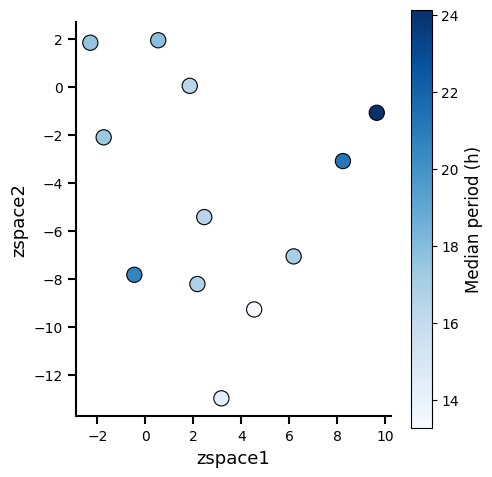

In [ ]:


# 1) Median period per cluster (from bootstrap results)
cluster_median_period = df.median(axis=0)
cluster_median_period.index = labels  

# 2) Add median period to each cell
data.obs['median_period'] = data.obs['node_id'].map(cluster_median_period)

# 3) Median z-space coordinates per cluster
cluster_coords = (
    data.obs
    .groupby('node_id')[['Z_space1', 'Z_space2']]
    .median()
)
cluster_coords['median_period'] = cluster_coords.index.map(cluster_median_period)

# 4) Plot one dot per cluster at median (zspace1, zspace2), colored by median period
fig, ax = plt.subplots(figsize=(5, 5))

sc = ax.scatter(
    cluster_coords['Z_space1'],
    cluster_coords['Z_space2'],
    c=cluster_coords['median_period'],
    cmap='Blues',
    s=120,
    edgecolor='black',
    linewidth=0.8
)

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label('Median period (h)', fontsize=12)

ax.set_xlabel('zspace1', fontsize=13)
ax.set_ylabel('zspace2', fontsize=13)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(axis="both", width=1.5, length=6)

ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()


In [ ]:


# 1) Median period per cluster (from bootstrap results)
cluster_median_period = df.median(axis=0)
cluster_median_period.index = labels  # ensure alignment with data.obs['cluster']

# 2) Add median period to each cell
data.obs['median_period'] = data.obs['node_id'].map(cluster_median_period)

# 3) Median z-space coordinates per cluster
cluster_coords = (
    data.obs
    .groupby('node_id')[['Z_space1', 'Z_space2']]
    .median()
)
cluster_coords['median_period'] = cluster_coords.index.map(cluster_median_period)


In [14]:
edges = [
    (0, 1), (1, 9), (9, 10), 
    (1, 2), (2, 3), (3, 4), 
    (2, 5), (5, 6), (1, 7), 
    (7, 11), (11, 8)
]

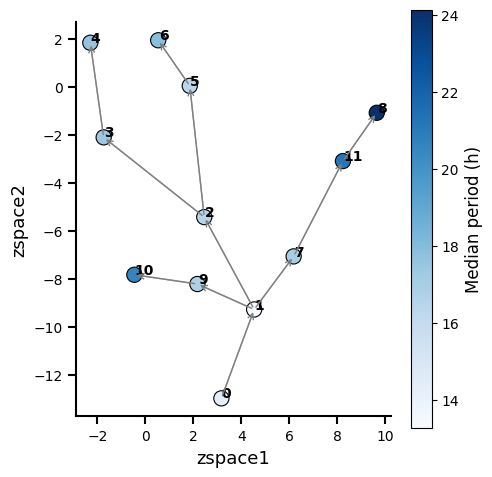

In [ ]:
# --- Plot clusters with median period ---
fig, ax = plt.subplots(figsize=(5, 5))

sc = ax.scatter(
    cluster_coords['Z_space1'],
    cluster_coords['Z_space2'],
    c=cluster_coords['median_period'],
    cmap='Blues',
    s=120,
    edgecolor='black',
    linewidth=0.8
)

# Annotate each cluster with node_id
for node_id, (x, y) in cluster_coords[['Z_space1', 'Z_space2']].iterrows():
    ax.text(
        x + 0.02, 
        y + 0.02,
        str(node_id),
        fontsize=10,
        weight='bold',
        color='black'
    )

# --- Draw edges between nodes ---
for source, target in edges:
    if source in cluster_coords.index and target in cluster_coords.index:
        x0, y0 = cluster_coords.loc[source, ['Z_space1', 'Z_space2']]
        x1, y1 = cluster_coords.loc[target, ['Z_space1', 'Z_space2']]
        ax.plot([x0, x1], [y0, y1], color='gray', linewidth=1, zorder=0, alpha=0.7)
        ax.annotate(
            '', xy=(x1, y1), xytext=(x0, y0),
            arrowprops=dict(arrowstyle='->', color='gray', lw=1)
        )

# Colorbar
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label('Median period (h)', fontsize=12)

# Axis styling
ax.set_xlabel('zspace1', fontsize=13)
ax.set_ylabel('zspace2', fontsize=13)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(axis="both", width=1.5, length=6)
ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()


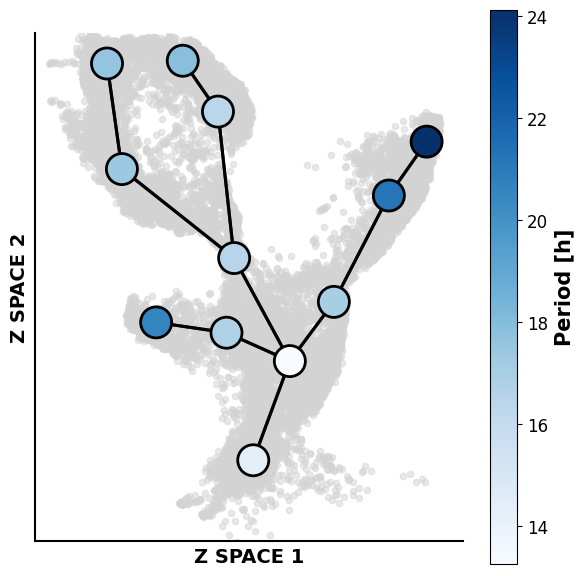

In [ ]:
import matplotlib.pyplot as plt

# -------------------------------------------------
# USER SETTINGS
# -------------------------------------------------
xlim = (-5, 11)
ylim = (-16, 3)

edge_color = 'black'
edge_lw = 2.2
edge_alpha = 0.9

# -------------------------------------------------
# Reattribute cluster IDs
# -------------------------------------------------
cluster_map = {0:0, 1:1, 9:2, 10:3, 7:4, 11:5, 8:6, 2:7, 3:8, 4:9, 5:10, 6:11}

cluster_coords['cluster_id'] = cluster_coords.index.map(cluster_map)
cluster_coords = cluster_coords.sort_values('cluster_id')

data.obs['node_id'] = data.obs['node_id'].map(cluster_map)

# -------------------------------------------------
# Plot
# -------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 6))

# Background cells
ax.scatter(
    data.obs['Z_space1'],
    data.obs['Z_space2'],
    color='lightgrey',
    s=20,
    alpha=0.5,
    zorder=0
)

# -------------------------------------------------
# Draw edges FIRST 
# -------------------------------------------------
for source, target in edges:
    if source in cluster_coords.index and target in cluster_coords.index:
        x0, y0 = cluster_coords.loc[source, ['Z_space1', 'Z_space2']]
        x1, y1 = cluster_coords.loc[target, ['Z_space1', 'Z_space2']]

        ax.plot(
            [x0, x1], [y0, y1],
            color=edge_color,
            linewidth=edge_lw,
            alpha=edge_alpha,
            zorder=1
        )

        ax.annotate(
            '',
            xy=(x1, y1),
            xytext=(x0, y0),
            arrowprops=dict(
                arrowstyle='->',
                color=edge_color,
                lw=edge_lw,
                alpha=edge_alpha
            ),
            zorder=1
        )

# -------------------------------------------------
# Plot cluster nodes ON TOP
# -------------------------------------------------
sc = ax.scatter(
    cluster_coords['Z_space1'],
    cluster_coords['Z_space2'],
    c=cluster_coords['median_period'],
    cmap='Blues',
    s=500,
    edgecolor='black',
    linewidth=2,
    zorder=3
)


# -------------------------------------------------
# Axis limits
# -------------------------------------------------
ax.set_xlim(xlim)
ax.set_ylim(ylim)

# -------------------------------------------------
# Colorbar
# -------------------------------------------------
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label('Period [h]', fontsize=15, weight='bold')  
cbar.ax.tick_params(labelsize=12) 

# -------------------------------------------------
# Styling
# -------------------------------------------------
ax.set_xlabel('Z SPACE 1', fontsize=14, weight='bold')
ax.set_ylabel('Z SPACE 2', fontsize=14, weight='bold')
ax.set_xticks([])
ax.set_yticks([])

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)

ax.set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.show()


In [18]:
data.obs.to_csv('INPUT/scRNAseq/df_node_period_continuous.csv')

In [22]:
import numpy as np

# cluster_map: old ID -> new ID
cluster_map = {0:0, 1:1, 9:2, 10:3, 7:4, 11:5, 8:6, 2:7, 3:8, 4:9, 5:10, 6:11}

# Apply map to cluster_coords
cluster_coords['cluster_id'] = cluster_coords.index.map(cluster_map)

# Map the edges to the new cluster IDs
edges_mapped = []
for source, target in edges:
    if source in cluster_map and target in cluster_map:
        new_source = cluster_map[source]
        new_target = cluster_map[target]
        edges_mapped.append((new_source, new_target))

edges_mapped = np.array(edges_mapped, dtype=int)

# Node coordinates in new order (sorted by cluster_id)
cluster_coords_sorted = cluster_coords.sort_values('cluster_id')
node_xy = cluster_coords_sorted[['Z_space1', 'Z_space2']].to_numpy()
node_values = cluster_coords_sorted['median_period'].to_numpy()


np.savez(
    "INPUT/scRNAseq/Continuous_traj_periods_TREE_core.npz",
    node_xy=node_xy,
    node_values=node_values,
    edges=edges_mapped
)


In [20]:
import numpy as np

# Convert to numpy arrays
node_xy = cluster_coords[['Z_space1', 'Z_space2']].to_numpy()
node_values = cluster_coords['median_period'].to_numpy()
connections = np.array(edges, dtype=int)  # edges as Nx2 array

# Save to .npz
np.savez(
    "INPUT/scRNAseq/Continuous_traj_periods_TREE_core.npz",
    node_xy=node_xy,
    node_values=node_values,
    edges=connections
)
